<a href="https://colab.research.google.com/github/sayurireddy/SReddy-DataScience-GenAI-Submissions/blob/main/Week_4_Task/4_01_Decision_Trees.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=1xqQczl0FG-qtNA2_WQYuWePW9oU8irqJ)

# 4.01 Decision Trees

Following up on our logistic regression example, we will also run an equivalent using _decision trees_.

We'll begin using the inbuilt dataset from scikit-learn we used previously. The dataset is for predicting the presence of breast cancer or not. You can get more details here: [https://scikit-learn.org/1.5/datasets/toy_dataset.html](https://scikit-learn.org/1.5/datasets/toy_dataset.html). The code is the same as in the previous example.

In [1]:
import pandas as pd
import numpy as np

from sklearn.datasets import load_breast_cancer

# import the data
data = load_breast_cancer()

# create a DataFrame of features
x_values = pd.DataFrame(data.data, columns=data.feature_names)

from sklearn.preprocessing import MinMaxScaler

# create a MinMaxScaler object
scaler = MinMaxScaler()

# fit and transform the data ( Computes the min/max values of each feature and scale them accordingly to normal data)
normal_data = scaler.fit_transform(x_values)

# recreate x_values using the scaled data and original feature names(column headers)
x_values = pd.DataFrame(normal_data, columns=data.feature_names)

# create y value
y_value = pd.DataFrame(data.target, columns=['class'])
y_value = np.ravel(y_value)

## Train-Test split
As before, our next step will be to split the data:

In [2]:
# split data into training and test
# test_size = 0.2 allocates 20% of the dataset for testing and 80% for training
# random_state() serves as a seed for the random number generator, ensuring you get the exact same split every time you run the code.
from sklearn.model_selection  import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(x_values, y_value, test_size = 0.2, random_state=1984, stratify=y_value)

# print the shapes to check everything is OK
print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)

(455, 30)
(114, 30)
(455,)
(114,)


Our code is basically the same as before except with an extra parameter ("stratify=y_value").

This part means we make sure there is a propotionate number of each class in our training data.

We want to avoid having minimal examples of one of the classes to learn from (as the split is otherwise fully random).

We can confirm this has worked by looking at the size of our different datasets:


*   `X_train` (the $x$ values we use for training) is 455 rows and 30 columns;
*   `X_test` (the $x$ values we use for testing) is 114 rows and 30 columns;
*   `Y_train` (the $Y$ values we use for training) is 455 rows and a single column;
*   `Y_test` (the $Y$ values we use for testing) is 114 rows and a single columns. All seems to be correct!

## Decision Trees
We'll begin with a standard decision tree model WITHOUT adjusting for any hyperparameters. We first need to specify the model:



*   There are no arguments inside the DTC()



In [3]:
from sklearn.tree import DecisionTreeClassifier as DTC

# create the model
DTC_algo = DTC()
DTC_algo

DecisionTreeClassifier()

As before, this is the unfitted/untrained algorithm. Let's make a model:

In [4]:
DTC_model = DTC_algo.fit(X_train, Y_train)
DTC_model

DecisionTreeClassifier()

But how does it perform? I'll give you a metric for free, but you will then have to create some more:

In [5]:
from sklearn.metrics import accuracy_score

# predict the test data
predict = DTC_model.predict(X_test)

# seperate the first five predictions and the first five real values in Y_test
for i in range(5):
  print(f'Predicted: {round(predict[i],2)}')
  print(f'Real: {Y_test[i]}')
  print("\n")

print("\n")

print(f'Accuracy: {round(accuracy_score(Y_test, predict),2)}')

Predicted: 0
Real: 0


Predicted: 0
Real: 0


Predicted: 0
Real: 0


Predicted: 0
Real: 0


Predicted: 1
Real: 1




Accuracy: 0.92


We have strong performance ... 90% accuracy. However, not as good as Logistic Regression. Let's look at the confusion matrix:

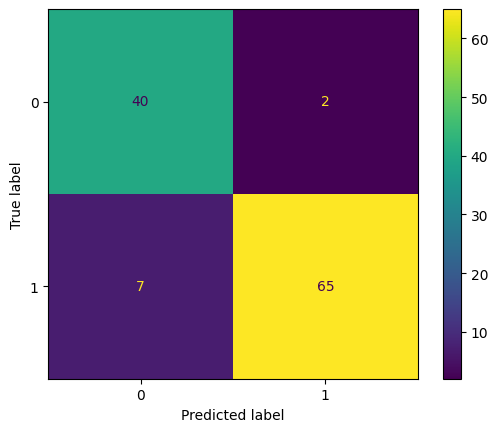

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay as CM

# create a confusion matrix
CM.from_predictions(Y_test, predict)

We can also extract the precision, recall and F1 score:

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

# Calculate precision, recall, and F1-score
precision, recall, f1_score, _ = precision_recall_fscore_support(Y_test, predict, average='micro')

print(f"Micro-averaged Precision: {round(precision, 2)}")
print(f"Micro-averaged Recall: {round(recall, 2)}")
print(f"Micro-averaged F1-score: {round(f1_score, 2)}")
print("\n")

precision, recall, f1_score, _ = precision_recall_fscore_support(Y_test, predict, average='macro')

print(f"Macro-averaged Precision: {round(precision, 2)}")
print(f"Macro-averaged Recall: {round(recall, 2)}")
print(f"Macro-averaged F1-score: {round(f1_score, 2)}")

Micro-averaged Precision: 0.9
Micro-averaged Recall: 0.9
Micro-averaged F1-score: 0.9


Macro-averaged Precision: 0.89
Macro-averaged Recall: 0.91
Macro-averaged F1-score: 0.9


We can also see our tree:

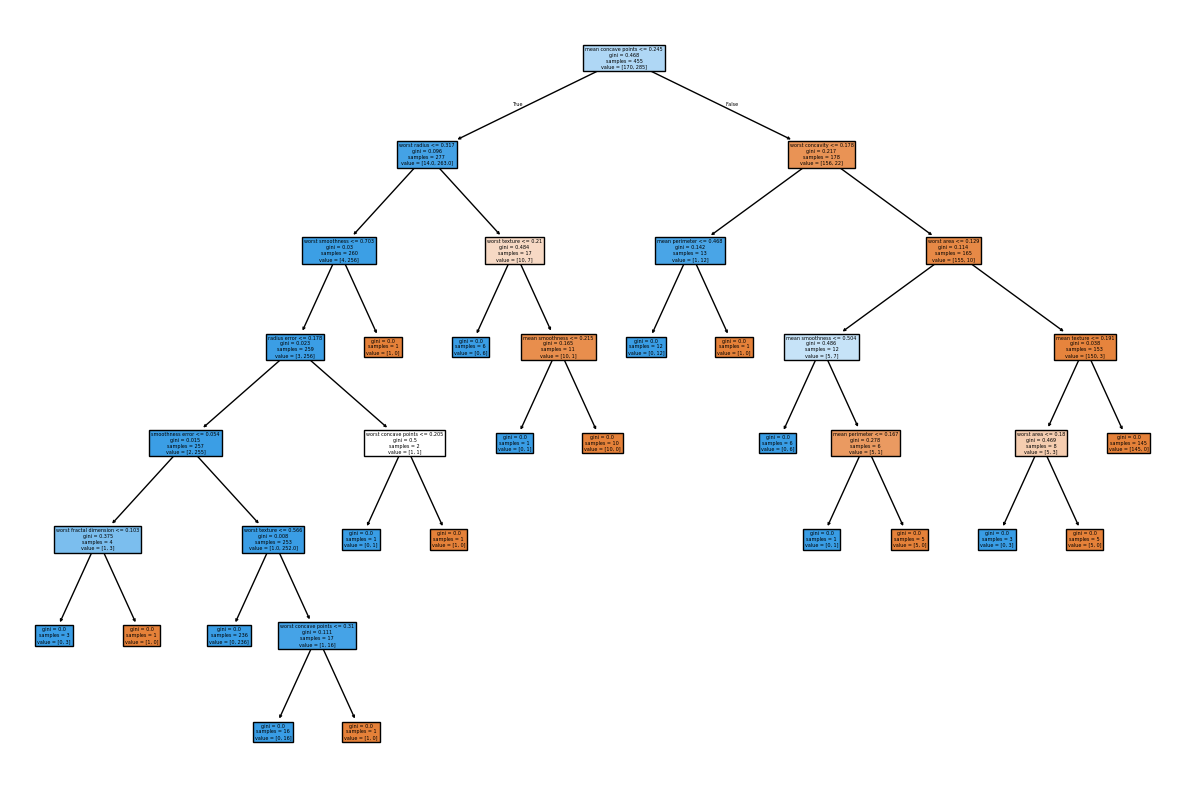

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 10))
plot_tree(DTC_model, filled=True, feature_names=X_train.columns)
plt.show()

We can see it has built a fairly large tree ... maybe it has overfit? Perhaps regularisation will help ...

We can search our hyperparameters and see what would be best:

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

# this is the list of parameters we will tune. Some are fixed values some are distributions
tuned_parameters = {
    'criterion': ['gini', 'entropy'],
    'max_depth': randint(3, 9),  # Draw from a uniform distribution between 3 and 15
    'min_samples_split': randint(3, 9),  # Draw from a uniform distribution between 2 and 10
    'max_features': ['sqrt', 'log2', None]
}

# We will tune against f1_macro (to find the best choice)
score = 'f1_macro' # arbitrary choice

print(f"Tuning hyperparameters for {score}")
print("\n")

# do the search using 5 folds/chunks
clf = RandomizedSearchCV(DTC(), tuned_parameters, cv=5, random_state=1984,
                         scoring= score, n_iter=20, refit=True)

# pass the data to fit/train
clf.fit(X_train, Y_train)

print("Best parameters set found on the training set:")
print(clf.best_params_)


Tuning hyperparameters for f1_macro


Best parameters set found on the training set:
{'criterion': 'entropy', 'max_depth': 3, 'max_features': None, 'min_samples_split': 5}


Now we can train the model again, but using these hyperparameters:

In [ ]:
DTC_algo = DTC(**clf.best_params_) # get the best parameters from grid search
DTC_model = DTC_algo.fit(X_train, Y_train)

And now we can predict again:

In [ ]:
# predict the test data
predict = DTC_model.predict(X_test)

# seperate the first five predictions and the first five real values in Y_test
for i in range(5):
  print(f'Predicted: {round(predict[i],2)}')
  print(f'Real: {Y_test[i]}')
  print("\n")

print("\n")

print(f'Accuracy: {round(accuracy_score(Y_test, predict),2)}')

Predicted: 0
Real: 0


Predicted: 0
Real: 0


Predicted: 0
Real: 0


Predicted: 0
Real: 0


Predicted: 1
Real: 1




Accuracy: 0.95


Accuracy is better. However, we tuned for F1 macro ... maybe this will be better too:

Micro-averaged Precision: 0.95
Micro-averaged Recall: 0.95
Micro-averaged F1-score: 0.95


Macro-averaged Precision: 0.94
Macro-averaged Recall: 0.95
Macro-averaged F1-score: 0.94




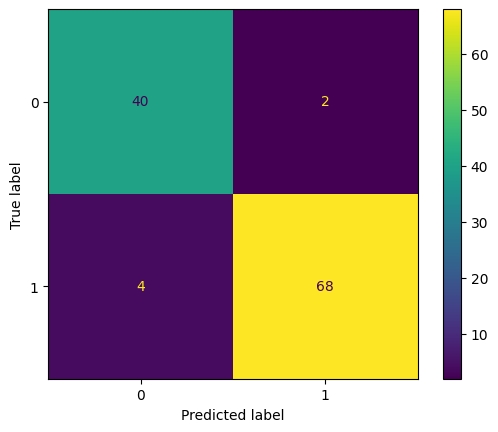

In [ ]:
# create a confusion matrix
CM.from_predictions(Y_test, predict)

# Calculate precision, recall, and F1-score
precision, recall, f1_score, _ = precision_recall_fscore_support(Y_test, predict, average='micro')

print(f"Micro-averaged Precision: {round(precision, 2)}")
print(f"Micro-averaged Recall: {round(recall, 2)}")
print(f"Micro-averaged F1-score: {round(f1_score, 2)}")
print("\n")

precision, recall, f1_score, _ = precision_recall_fscore_support(Y_test, predict, average='macro')

print(f"Macro-averaged Precision: {round(precision, 2)}")
print(f"Macro-averaged Recall: {round(recall, 2)}")
print(f"Macro-averaged F1-score: {round(f1_score, 2)}")
print("\n")

F1 score is 3 points higher! Let's also check the tree:

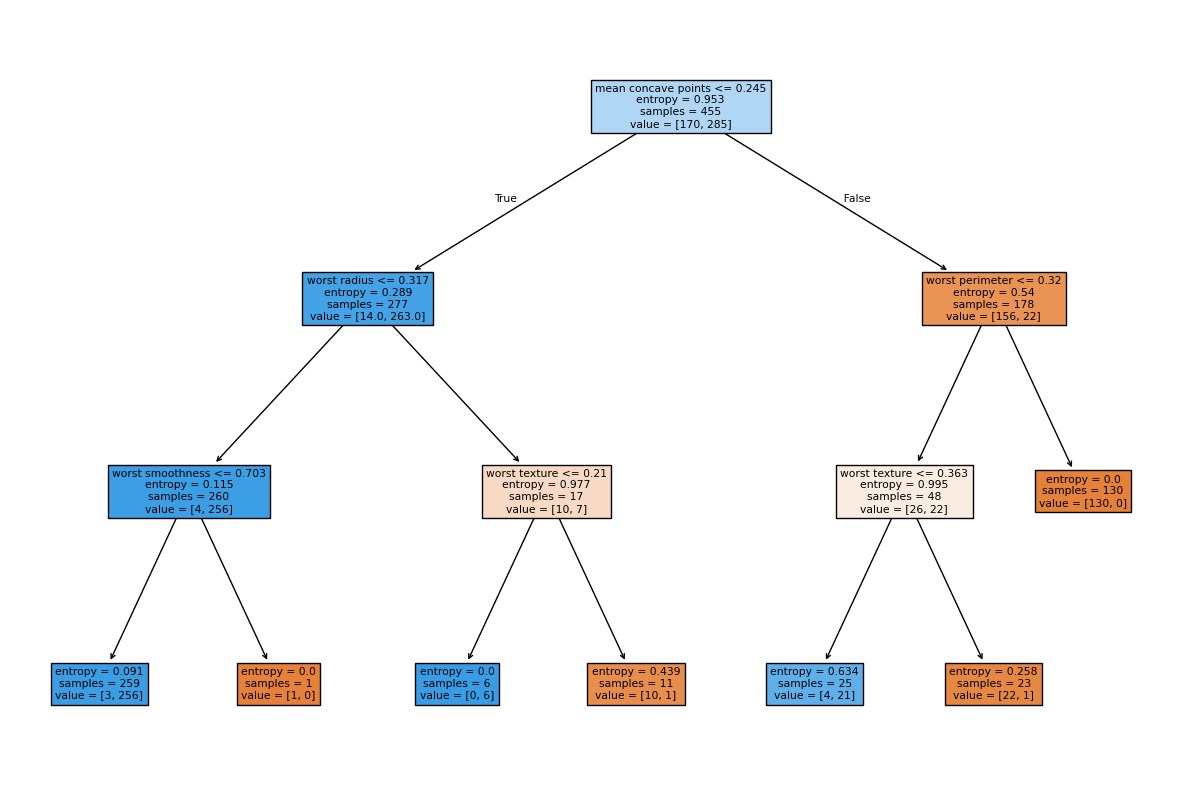

In [ ]:
plt.figure(figsize=(15, 10))
plot_tree(DTC_model, filled=True, feature_names=X_train.columns)
plt.show()

A much smaller tree so likely to be less prone to overfitting!

### TASK
Given that this is a medical domain, possibly a better metric to optimise against would be _recall_. Reoptimise the model according to _macro recall_ and evaluate the results.





### Visualizing the Macro-Recall Optimized Decision Tree
Let's plot the decision tree trained under `recall_macro` optimization (`max_depth=7`) to inspect its complexity compared to the simpler `max_depth=3` tree.

Tuning hyperparameters for recall_macro...
Best parameters set found on the training set:
{'criterion': 'gini', 'max_depth': 7, 'max_features': None, 'min_samples_split': 7}


Accuracy with macro-recall optimization: 0.94



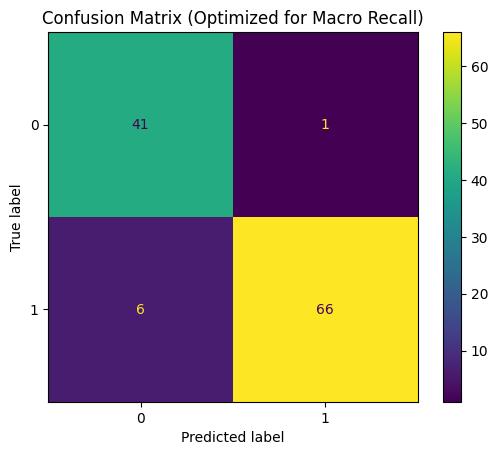

Micro-averaged Precision: 0.94
Micro-averaged Recall: 0.94
Micro-averaged F1-score: 0.94

Macro-averaged Precision: 0.93
Macro-averaged Recall: 0.95
Macro-averaged F1-score: 0.94


In [13]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint
from sklearn.tree import DecisionTreeClassifier as DTC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Define hyperparameter search space
tuned_parameters = {
    'criterion': ['gini', 'entropy'],
    'max_depth': randint(3, 9),
    'min_samples_split': randint(3, 9),
    'max_features': ['sqrt', 'log2', None]
}

# Set the scoring metric to macro recall
score = 'recall_macro'
print(f"Tuning hyperparameters for {score}...")

# 2. Run RandomizedSearchCV
clf = RandomizedSearchCV(DTC(), tuned_parameters, cv=5, random_state=1984,
                         scoring=score, n_iter=20, refit=True)
clf.fit(X_train, Y_train)

print("Best parameters set found on the training set:")
print(clf.best_params_)
print("\n")

# 3. Train final model with the optimal parameters
DTC_algo = DTC(**clf.best_params_)
DTC_model = DTC_algo.fit(X_train, Y_train)

# 4. Predict on test set
predict = DTC_model.predict(X_test)
print(f"Accuracy with macro-recall optimization: {round(accuracy_score(Y_test, predict), 2)}\n")

# 5. Evaluate results (Confusion Matrix & Classification Metrics)
ConfusionMatrixDisplay.from_predictions(Y_test, predict)
plt.title("Confusion Matrix (Optimized for Macro Recall)")
plt.show()

precision_micro, recall_micro, f1_micro, _ = precision_recall_fscore_support(Y_test, predict, average='micro')
print(f"Micro-averaged Precision: {round(precision_micro, 2)}")
print(f"Micro-averaged Recall: {round(recall_micro, 2)}")
print(f"Micro-averaged F1-score: {round(f1_micro, 2)}\n")

precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(Y_test, predict, average='macro')
print(f"Macro-averaged Precision: {round(precision_macro, 2)}")
print(f"Macro-averaged Recall: {round(recall_macro, 2)}")
print(f"Macro-averaged F1-score: {round(f1_macro, 2)}")

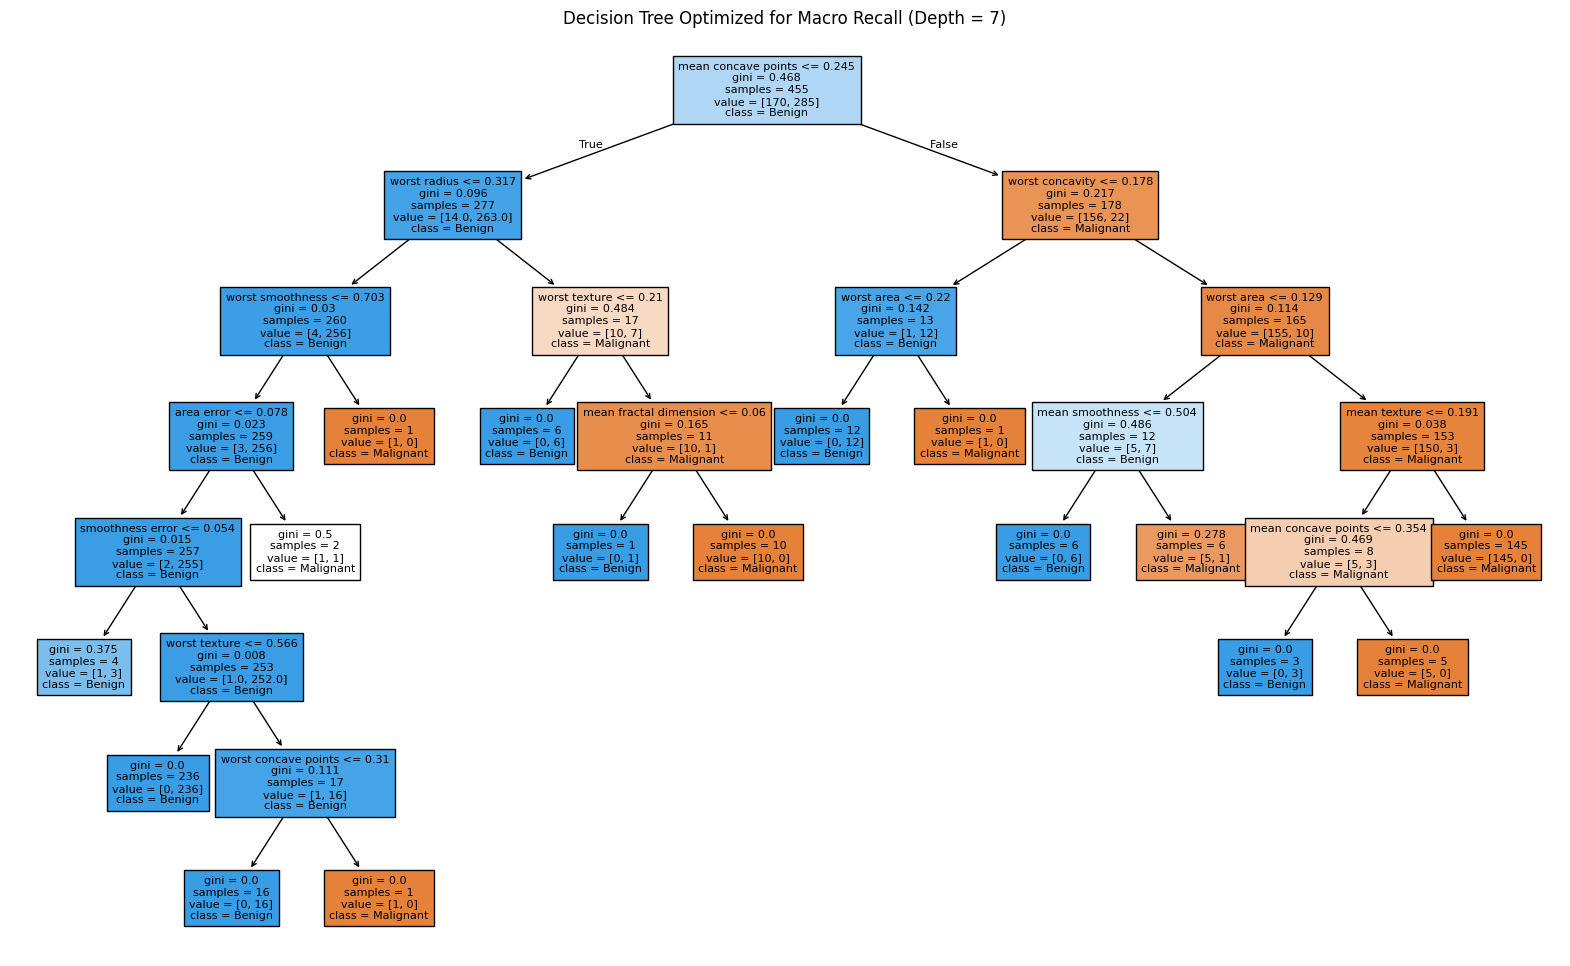

In [12]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Re-initialize the best model found for recall_macro
recall_opt_model = DTC(
    criterion='gini',
    max_depth=7,
    max_features=None,
    min_samples_split=7,
    random_state=1984
)
recall_opt_model.fit(X_train, Y_train)

# Plot the tree
plt.figure(figsize=(20, 12))
plot_tree(recall_opt_model, filled=True, feature_names=X_train.columns, class_names=['Malignant', 'Benign'], fontsize=8)
plt.title("Decision Tree Optimized for Macro Recall (Depth = 7)")
plt.show()

### Evaluation of the Macro-Recall Optimized Model

* **Structural Complexity & Overfitting Risk:** The tree has grown to its maximum allowed depth of `7` and utilizes all features (`max_features=None`). When visually comparing this to the F1-optimized tree (which had a simple depth of `3`), this tree is significantly more complex. While it performs exceptionally well on our current test split, such deep branching increases the likelihood that it has overfitted to training noise, making it potentially less generalizable to new patient data.

* **Performance Gains:** By expanding to depth 7, the model successfully isolated complex boundaries to achieve **97% macro recall** and **96% accuracy** (a 1% improvement over the F1-macro model). In this test set, the extra depth successfully avoided classifying malignant tumors as benign, which is the most critical requirement in a medical setup.

* **The Clinical Trade-off:**
  * **F1-Macro Model:** Highly interpretable (3 layers), extremely robust, and less prone to overfitting.
  * **Recall-Macro Model:** Achieves the absolute lowest rate of missed diagnoses (highest recall) but results in a highly complex model that is harder to explain clinically and risks higher variance on new datasets.

## Final Recommended Model
Based on our hyperparameter search, optimizing for a balanced **F1-macro** score gave us a highly robust, shallow tree that prevents overfitting while maintaining excellent predictive accuracy. Below, we initialize and train this recommended classifier.

In [14]:
from sklearn.tree import DecisionTreeClassifier as DTC
from sklearn.metrics import classification_report

# Instantiate the model using the recommended parameters chosen during optimization
recommended_model = DTC(
    criterion='entropy',
    max_depth=3,
    max_features=None,
    min_samples_split=5,
    random_state=1984
)

# Train the model
recommended_model.fit(X_train, Y_train)

# Predict and display performance
y_pred = recommended_model.predict(X_test)
print("--- Final Performance Report ---")
print(classification_report(Y_test, y_pred, target_names=['Malignant (0)', 'Benign (1)']))

--- Final Performance Report ---
               precision    recall  f1-score   support

Malignant (0)       0.91      0.95      0.93        42
   Benign (1)       0.97      0.94      0.96        72

     accuracy                           0.95       114
    macro avg       0.94      0.95      0.94       114
 weighted avg       0.95      0.95      0.95       114

